# Company A — Churn-Risk Targeting PoC
**GCI World 2026 · Final Assignment · Shafayet Jamil**

Reproducible analysis behind the slide deck. Run top-to-bottom (≈5–10 min on a laptop / Colab CPU).

| # | Section | Question it answers |
|---|---|---|
| 1 | Market context | Why does churn matter for a mature mobile operator? |
| 2 | Setup & data loading | What do we have? |
| 3 | Data quality | What must be cleaned? Any leakage? |
| 4 | EDA | Which customer signals separate churners from stayers? |
| 5 | Problem definition | What exactly do we predict, and how do we score it? |
| 6 | Feature engineering | Which derived signals capture *behaviour change*? |
| 7 | Modelling | Which model ranks churn risk best? |
| 8 | Evaluation & interpretation | How good is it, and *why* does it predict churn? |
| 9 | Business proposal | Who to target, with what, and what is it worth? |
| 10 | Risks & next steps | |
| 11 | References | |

### Executive summary
- **Problem:** Company A loses customers to competitors in a saturated market, but has no way to decide *whom* to retain or *with what*. Retention budgets spent blindly are wasted on customers who would have stayed anyway.
- **What drives churn (EDA + model):** (1) **ageing handsets** — churn jumps from ~40% to ~55–60% once a handset passes ~1 year; (2) **falling usage** relative to the customer's own history; (3) the **contract-end window** at ~11–12 months tenure (churn 62–65%); (4) **low-commitment plans** (low recurring charge, cheap handsets). Network quality is *not* a main driver.
- **Model:** **LightGBM** gradient-boosted trees, chosen over Logistic Regression, Random Forest and XGBoost. **Test ROC-AUC = 0.703** (5-fold CV 0.699 ± 0.003), **accuracy = 0.641** vs 0.50 baseline. The top-risk decile churns at **81% vs 18%** in the bottom decile (lift 1.6×).
- **Key commercial insight:** at a realistic **2% monthly churn**, a blanket retention offer **loses ≈$4.1M/year** and random targeting also loses money. Ranking by risk alone barely breaks even, because the highest-risk customers are often **low-revenue** accounts.
- **Proposal:** a monthly **expected-value targeting rule** (re-calibrated churn risk × customer value − offer cost) with **segment-specific offers** — handset upgrade for ageing devices, early renewal for contract-end, plan right-sizing for usage decliners. It selects ~6% of the base and turns the campaign **profitable (≈ +$0.13M/year, ROI 0.64 on a 100k base under conservative assumptions)**, scaling with the save rate measured in a pilot.

---
## 1. Introduction & Market Analysis

**Company A** is a wireless operator with ~100,000 subscribers and rich usage/billing history but no in-house ML capability.

**Market facts that frame the problem**
- **The market is saturated.** GSMA reports ~5.6 billion unique mobile subscribers worldwide at the end of 2023 (≈69% of the global population), with subscriber growth slowing to low single digits [3]. In a saturated market, growth comes from *stealing* customers from rivals or *keeping* your own — churn is the central battleground.
- **Retention is cheaper than acquisition.** Acquiring a new customer is commonly estimated at **5–25× the cost** of retaining an existing one [2], and a 5-percentage-point increase in retention has been associated with a **25–95% increase in profits** [1].
- **Churn is predictable from behaviour.** The large-scale churn-modelling tournament analysed by Neslin et al. (2006) showed that models built on wireless-carrier usage, billing and equipment data materially outperform random targeting, and that the method used changes the profit of a retention campaign [6]. Verbeke et al. (2012) argue churn models should be judged on the *profit of the campaign they drive*, not just on accuracy [5].
- **Device upgrades are a churn moment.** Handset replacement cycles and 5G migration (Ericsson projects 5G to become the dominant subscription type during the decade [4]) push customers to re-evaluate their operator when their handset ages — the point at which competitors' handset subsidies are most attractive.

**Working hypotheses before looking at the data**
1. Customers with **old handsets** are more likely to leave (upgrade-driven switching).
2. **Falling usage** is an early warning signal (customer is already moving traffic to another SIM / operator).
3. **Price/plan mismatch** (overage, recurring charge relative to usage) drives dissatisfaction.
4. **Network quality** problems (dropped / blocked calls) drive churn.

The EDA below tests each of these.

---
## 2. Setup & Data Loading

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, precision_score,
                             recall_score, confusion_matrix, roc_curve, log_loss)
from xgboost import XGBClassifier
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"stayed": "#4C72B0", "churned": "#DD8452"}
SEED = 42
np.random.seed(SEED)

The data folder `telecom/` is expected next to this notebook. On Google Colab, mount Drive first and set `COLAB_DIR` to the folder that contains `telecom/`.

In [2]:
# --- Colab only: uncomment the two lines below and edit COLAB_DIR ---
# from google.colab import drive; drive.mount('/content/drive')
COLAB_DIR = Path("/content/drive/MyDrive/Final Assignment")

candidates = [Path.cwd(), Path.cwd().parent, COLAB_DIR]
DATA_DIR = next((p / "telecom" for p in candidates if (p / "telecom" / "Client.csv").exists()), None)
assert DATA_DIR is not None, "Could not find telecom/Client.csv — set COLAB_DIR"
print("Data folder:", DATA_DIR)

client = pd.read_csv(DATA_DIR / "Client.csv")
record = pd.read_csv(DATA_DIR / "Record.csv")
print("Client:", client.shape, "| Record:", record.shape)
print("Customer_ID unique in both:", client.Customer_ID.is_unique and record.Customer_ID.is_unique,
      "| identical ID sets:", set(client.Customer_ID) == set(record.Customer_ID))

df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print("Merged:", df.shape)
df.head(3)

Data folder: /home/user/final-assignment-gci/telecom


Client: (100000, 50) | Record: (100000, 51)
Customer_ID unique in both: True | identical ID sets: True
Merged: (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.0,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.0,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.0,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0


---
## 3. Data Quality

### 3.1 Types and missing values

77 numeric, 21 categorical columns
Categorical: ['new_cell', 'crclscod', 'asl_flag', 'prizm_social_one', 'area', 'dualband', 'refurb_new', 'hnd_webcap', 'ownrent', 'dwlltype', 'marital', 'infobase', 'HHstatin', 'dwllsize', 'ethnic', 'kid0_2', 'kid3_5', 'kid6_10', 'kid11_15', 'kid16_17', 'creditcd']


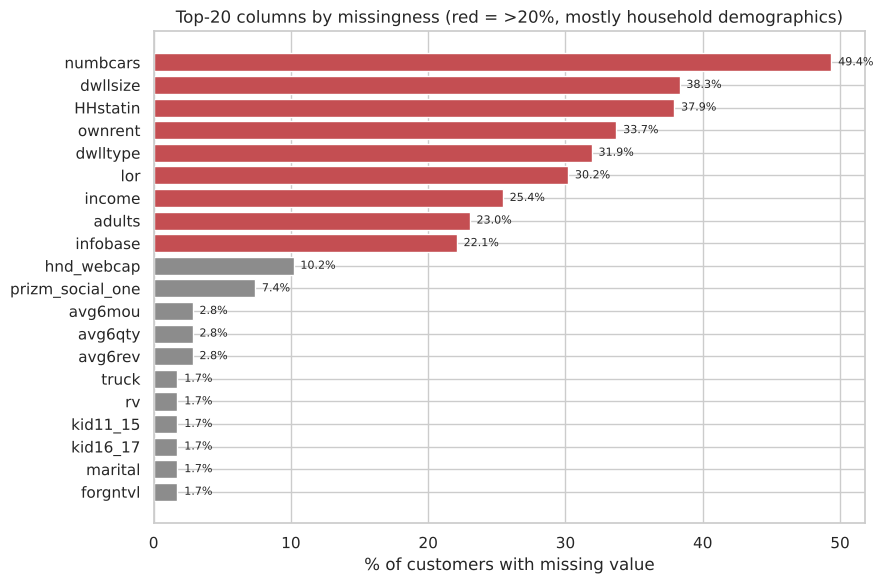

In [3]:
cat_cols_raw = df.select_dtypes(exclude="number").columns.tolist()
num_cols_raw = [c for c in df.select_dtypes(include="number").columns if c not in ("churn", "Customer_ID")]
print(f"{len(num_cols_raw)} numeric, {len(cat_cols_raw)} categorical columns")
print("Categorical:", cat_cols_raw)

miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0] * 100
fig, ax = plt.subplots(figsize=(9, 6))
top = miss.head(20)
ax.barh(top.index[::-1], top.values[::-1], color=["#C44E52" if v > 20 else "#8C8C8C" for v in top.values[::-1]])
ax.set_xlabel("% of customers with missing value")
ax.set_title("Top-20 columns by missingness (red = >20%, mostly household demographics)")
for i, v in enumerate(top.values[::-1]):
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center", fontsize=8)
plt.tight_layout(); plt.show()

**Reading:** missingness is concentrated in the third-party **household demographics** (`numbcars`, `dwllsize`, `HHstatin`, `ownrent`, `lor`, `income`, …: 20–50% missing). Usage and billing columns are almost complete. We will **not drop** these columns blindly: whether a customer could be matched to the demographic database may itself carry signal. Instead, missing values are kept as `NaN` (gradient-boosting handles them natively) and a *count of missing demographics* feature is added.

### 3.2 Implausible values

In [4]:
checks = {
    "eqpdays < 0 (handset age negative)": (df.eqpdays < 0).sum(),
    "rev_Mean < 0 (negative revenue)": (df.rev_Mean < 0).sum(),
    "totmrc_Mean < 0 (negative recurring charge)": (df.totmrc_Mean < 0).sum(),
    "rev_Mean > 1000 $/month": (df.rev_Mean > 1000).sum(),
}
display(pd.Series(checks, name="# customers").to_frame())
df[["rev_Mean", "mou_Mean", "totmrc_Mean", "eqpdays", "months", "change_mou", "custcare_Mean", "hnd_price"]].describe().T.round(1)

,# customers
eqpdays < 0 (handset age negative),133
rev_Mean < 0 (negative revenue),5
totmrc_Mean < 0 (negative recurring charge),23
rev_Mean > 1000 $/month,3


,count,mean,std,min,25%,50%,75%,max
rev_Mean,99643.0,58.7,46.3,-6.2,33.3,48.2,70.8,3843.3
mou_Mean,99643.0,513.6,525.2,0.0,150.8,355.5,703.0,12206.8
totmrc_Mean,99643.0,46.2,23.6,-26.9,30.0,45.0,60.0,410.0
eqpdays,99999.0,391.9,256.5,-5.0,212.0,342.0,530.0,1823.0
months,100000.0,18.8,9.7,6.0,11.0,16.0,24.0,61.0
change_mou,99109.0,-13.9,276.1,-3875.0,-87.0,-6.2,63.0,31219.2
custcare_Mean,100000.0,1.8,5.3,0.0,0.0,0.0,1.7,675.3
hnd_price,99153.0,101.9,61.0,10.0,30.0,100.0,150.0,500.0


**Reading:** a handful of negative handset ages / revenues (billing adjustments, data-entry errors) are set to `NaN`. Heavy right tails (revenue up to ~$3,800/month, minutes up to 12,000/month) are real heavy users — tree models are insensitive to them; for logistic regression we apply a signed-log transform, and for charts we bin by quantile so extreme values do not distort the picture.

### 3.3 Leakage check
A single feature that predicts churn "too well" would suggest it is recorded *after* the churn event. We compute the stand-alone ROC-AUC of every numeric column.

In [5]:
def single_auc(x, y):
    m = x.notna()
    a = roc_auc_score(y[m], x[m])
    return max(a, 1 - a)

uni_auc = pd.Series({c: single_auc(df[c], df.churn) for c in num_cols_raw}).sort_values(ascending=False)
print("Highest single-feature AUCs:")
print(uni_auc.head(10).round(3).to_string())

Highest single-feature AUCs:
eqpdays            0.574
hnd_price          0.558
totmrc_Mean        0.542
mou_opkv_Mean      0.541
mou_cvce_Mean      0.541
mou_Mean           0.539
iwylis_vce_Mean    0.536
mouiwylisv_Mean    0.536
complete_Mean      0.536
opk_vce_Mean       0.536


**Reading:** the best single column reaches an AUC of only ~0.6. No feature is "too good to be true", so there is **no evidence of target leakage**; churn is a multi-factor outcome that needs a multivariate model.

---
## 4. Exploratory Data Analysis

### 4.1 Target balance

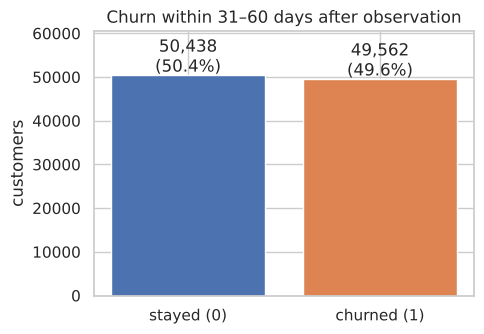

Overall churn rate: 49.6%


In [6]:
rate = df.churn.mean()
fig, ax = plt.subplots(figsize=(5, 3.5))
vc = df.churn.value_counts().sort_index()
ax.bar(["stayed (0)", "churned (1)"], vc.values, color=[PALETTE["stayed"], PALETTE["churned"]])
for i, v in enumerate(vc.values):
    ax.text(i, v + 800, f"{v:,}\n({v/len(df):.1%})", ha="center")
ax.set_ylim(0, vc.max() * 1.2); ax.set_ylabel("customers")
ax.set_title("Churn within 31–60 days after observation")
plt.tight_layout(); plt.show()
print(f"Overall churn rate: {rate:.1%}")

**Reading:** ~50% churn — far higher than the 1.5–3%/month typical of real operators. The sample was almost certainly **balanced by design** (churners over-sampled, as in the Duke/Teradata tournament data [6]). Consequences:
1. Accuracy is a usable metric here, but **ROC-AUC** (ranking quality, independent of the 50/50 sampling) is our primary metric.
2. When we translate results into money (Section 9) we **re-weight to a realistic base churn rate** rather than assume half the customers leave.

### 4.2 Testing the hypotheses: churn rate by numeric driver
Each panel splits customers into 10 equal-size groups (deciles) of a feature and shows the churn rate per group. Dashed line = average churn.

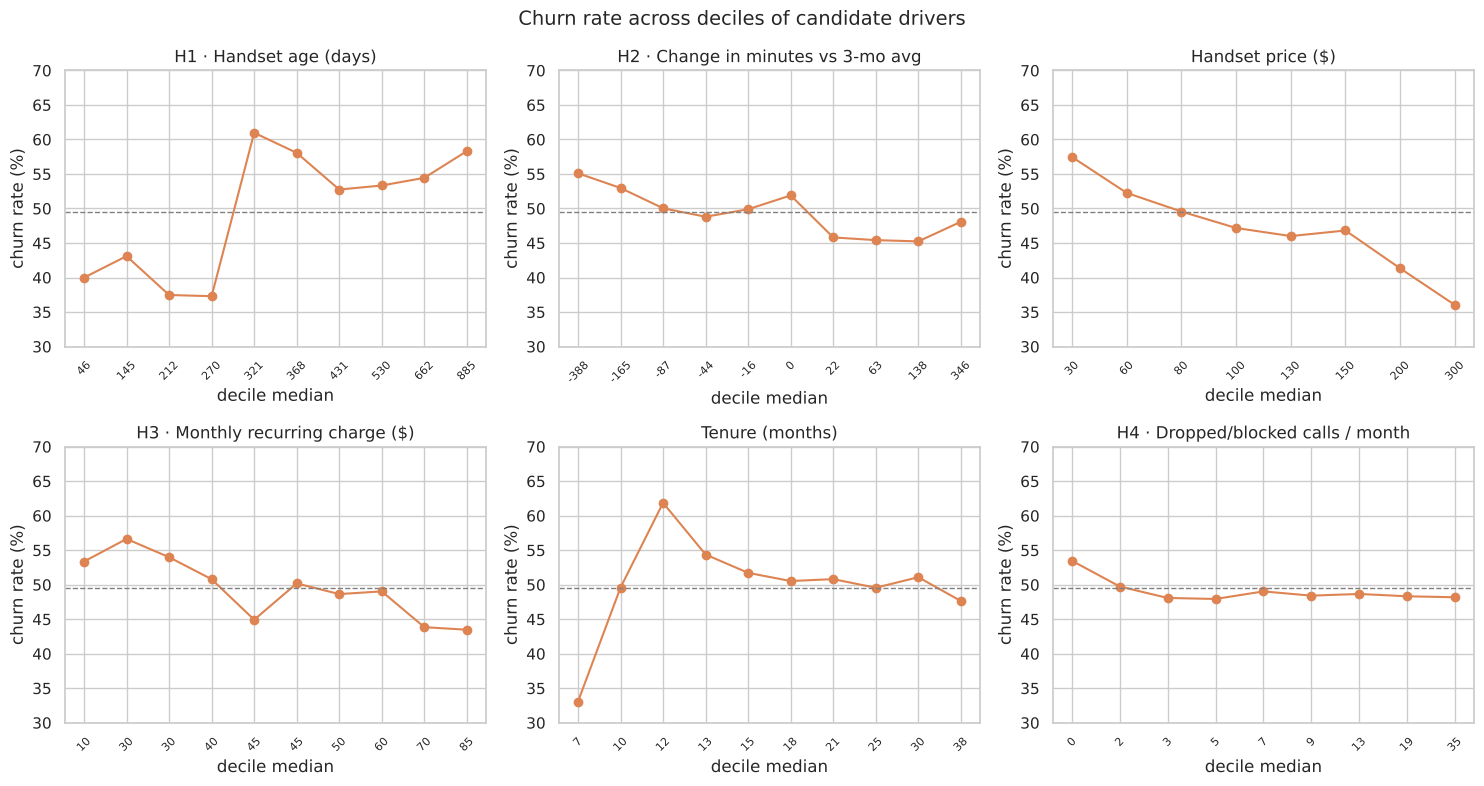

In [7]:
def churn_by_quantile(col, q=10, data=df):
    s = data[[col, "churn"]].dropna()
    s["bin"] = pd.qcut(s[col], q=q, duplicates="drop")
    g = s.groupby("bin", observed=True).agg(churn=("churn", "mean"), n=("churn", "size"), mid=(col, "median"))
    return g

drivers = {
    "eqpdays": "H1 · Handset age (days)",
    "change_mou": "H2 · Change in minutes vs 3-mo avg",
    "hnd_price": "Handset price ($)",
    "totmrc_Mean": "H3 · Monthly recurring charge ($)",
    "months": "Tenure (months)",
    "drop_blk_Mean": "H4 · Dropped/blocked calls / month",
}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.ravel(), drivers.items()):
    g = churn_by_quantile(col)
    ax.plot(range(len(g)), g.churn * 100, marker="o", color=PALETTE["churned"])
    ax.axhline(rate * 100, ls="--", color="grey", lw=1)
    ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{m:,.0f}" for m in g.mid], rotation=45, fontsize=8)
    ax.set_title(title); ax.set_ylabel("churn rate (%)"); ax.set_xlabel("decile median")
    ax.set_ylim(30, 70)
plt.suptitle("Churn rate across deciles of candidate drivers", fontsize=14)
plt.tight_layout(); plt.show()

In [8]:
summary = []
for col in drivers:
    g = churn_by_quantile(col)
    summary.append({"feature": col, "lowest-decile churn": g.churn.iloc[0], "highest-decile churn": g.churn.iloc[-1],
                    "spread (pp)": (g.churn.max() - g.churn.min()) * 100})
pd.DataFrame(summary).set_index("feature").style.format({"lowest-decile churn": "{:.1%}", "highest-decile churn": "{:.1%}", "spread (pp)": "{:.1f}"})

,lowest-decile churn,highest-decile churn,spread (pp)
feature,,,
eqpdays,40.0%,58.3%,23.7
change_mou,55.1%,48.1%,9.9
hnd_price,57.5%,36.0%,21.4
totmrc_Mean,53.4%,43.5%,13.2
months,33.1%,47.6%,28.8
drop_blk_Mean,53.5%,48.2%,5.5


**Reading (hypothesis by hypothesis):**
- **H1 Handset age — confirmed, strongest lever.** There is a clear **step at ~1 year**: customers with handsets younger than ~11 months churn at ~37–43%, while those past the 1-year mark churn at ~53–61%. This is the single strongest stand-alone signal (AUC 0.57).
- **H2 Usage decline — confirmed.** The decile with the sharpest drop in minutes has the highest churn; customers whose usage is stable or growing churn the least. Usage decline is an *early-warning* signal.
- **Handset price — cheaper handsets churn more** (low-value devices, low lock-in).
- **H3 Recurring charge — lower plans churn more**: low-commitment plans are easier to leave; heavy plan users are more locked-in.
- **Tenure** has a non-linear pattern (risk around typical contract-end months, ~10–12 months).
- **H4 Network quality — not supported.** Only the very lowest decile (customers with almost no calls) churns more; above that, more dropped/blocked calls go with slightly *lower* churn because the count scales with usage (heavy users drop more calls but are more loyal). We test a **rate** version in Section 6.

### 4.3 Contract-end effect: tenure in months

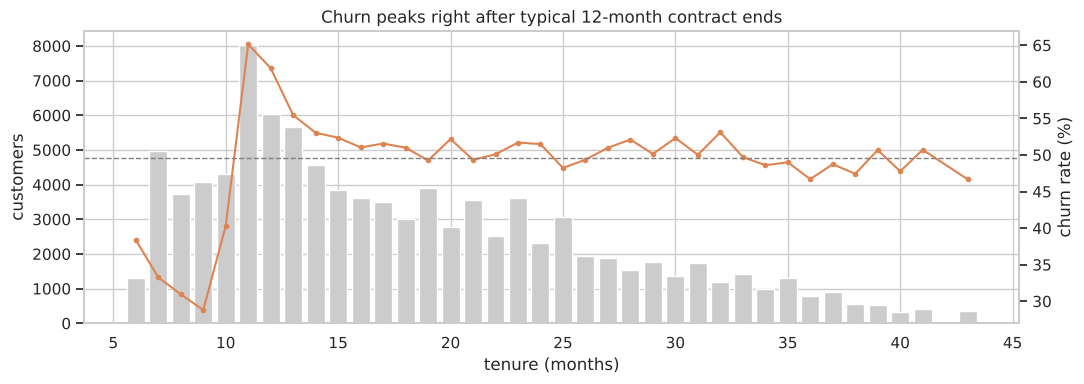

         mean  size
months             
11      0.651  8029
12      0.619  6033
13      0.554  5651
32      0.531  1194
14      0.530  4552


In [9]:
t = df.groupby("months").churn.agg(["mean", "size"]).query("size >= 300")
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(t.index, t["size"], color="#CCCCCC", label="customers")
ax1.set_ylabel("customers"); ax1.set_xlabel("tenure (months)")
ax2 = ax1.twinx()
ax2.plot(t.index, t["mean"] * 100, color=PALETTE["churned"], marker="o", ms=3, label="churn rate")
ax2.axhline(rate * 100, ls="--", color="grey", lw=1); ax2.set_ylabel("churn rate (%)"); ax2.grid(False)
ax1.set_title("Churn peaks right after typical 12-month contract ends")
plt.tight_layout(); plt.show()
print(t.sort_values("mean", ascending=False).head(5).round(3))

**Reading:** churn spikes at **~11–12 months** — the end of a one-year contract — and is lowest in the first months (customers still under contract). Timing matters: a retention offer must arrive **before** the contract-end window.

### 4.4 Categorical segments

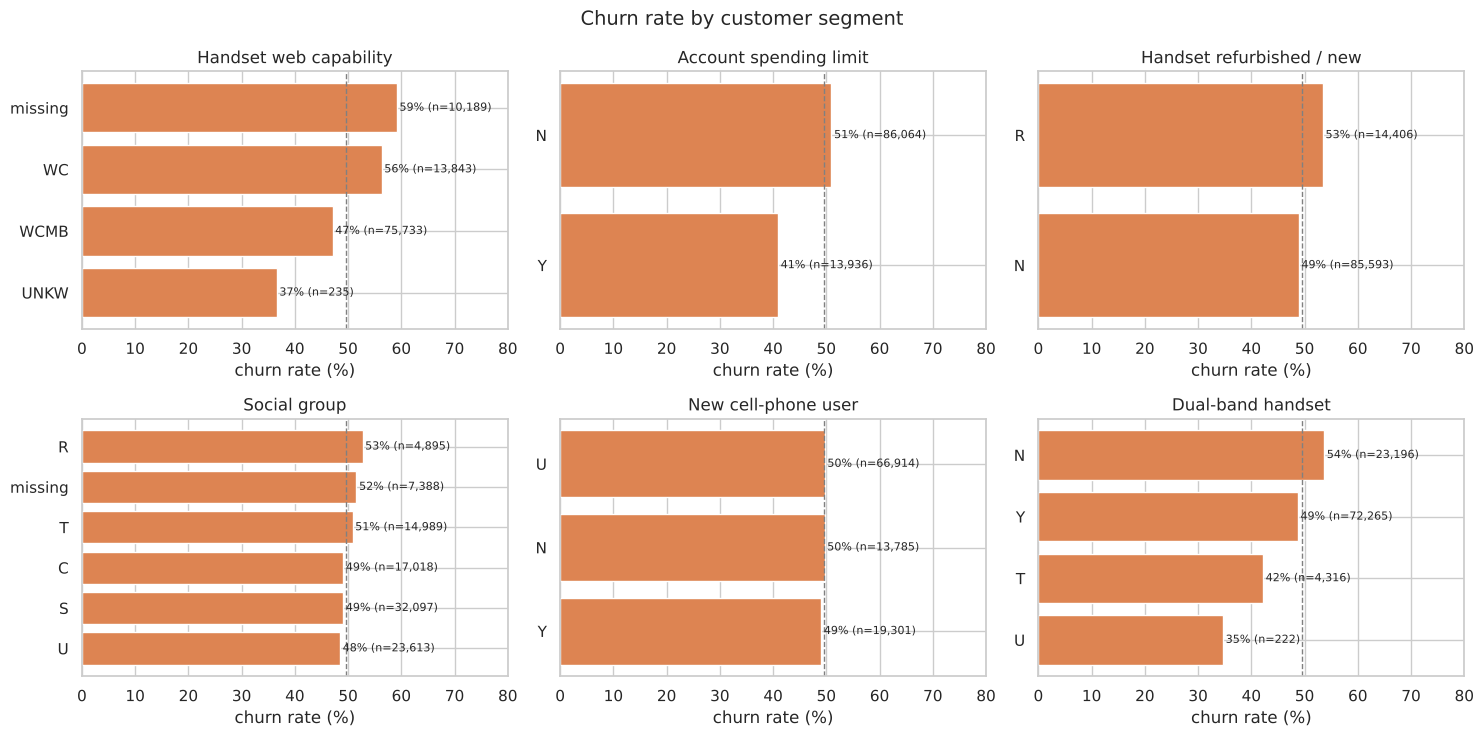

In [10]:
seg_cols = {"hnd_webcap": "Handset web capability", "asl_flag": "Account spending limit",
            "refurb_new": "Handset refurbished / new", "prizm_social_one": "Social group",
            "new_cell": "New cell-phone user", "dualband": "Dual-band handset"}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (col, title) in zip(axes.ravel(), seg_cols.items()):
    g = df.assign(**{col: df[col].fillna("missing")}).groupby(col).churn.agg(["mean", "size"])
    g = g[g["size"] >= 200].sort_values("mean")
    ax.barh(g.index.astype(str), g["mean"] * 100, color=PALETTE["churned"])
    ax.axvline(rate * 100, ls="--", color="grey", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100 + 0.5, i, f"{m:.0%} (n={n:,})", va="center", fontsize=8)
    ax.set_xlim(0, 80); ax.set_title(title); ax.set_xlabel("churn rate (%)")
plt.suptitle("Churn rate by customer segment", fontsize=14)
plt.tight_layout(); plt.show()

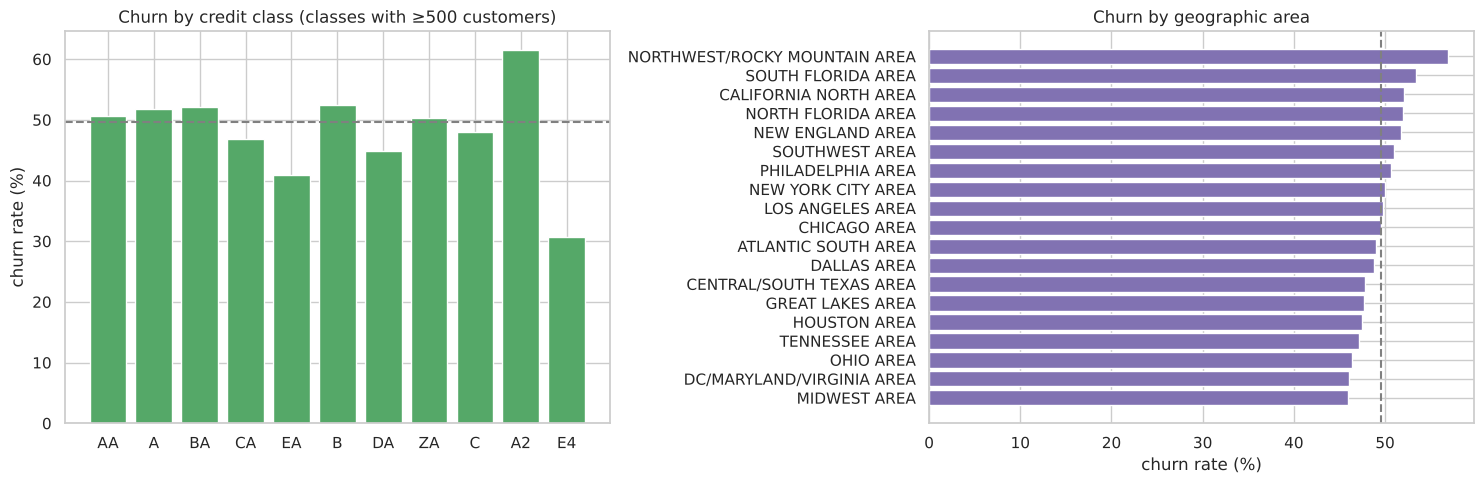

In [11]:
cc = df.groupby("crclscod").churn.agg(["mean", "size"]).query("size >= 500").sort_values("size", ascending=False)
area = df.groupby("area").churn.agg(["mean", "size"]).sort_values("mean")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(cc.index, cc["mean"] * 100, color="#55A868"); axes[0].axhline(rate * 100, ls="--", color="grey")
axes[0].set_title("Churn by credit class (classes with ≥500 customers)"); axes[0].set_ylabel("churn rate (%)")
axes[1].barh(area.index, area["mean"] * 100, color="#8172B2"); axes[1].axvline(rate * 100, ls="--", color="grey")
axes[1].set_title("Churn by geographic area"); axes[1].set_xlabel("churn rate (%)")
plt.tight_layout(); plt.show()

**Reading:**
- Customers whose handset web capability is **unknown/missing (59%) or "WC" (56%) churn most**, versus 47% for "WCMB" (the most common, newer handsets) — consistent with H1: older device generations churn more.
- Accounts **without a spending limit** churn more than those with one (spending-limited accounts are often prepaid/credit-controlled, with fewer switching options).
- **Refurbished handsets** churn more than new ones.
- Credit class and area show spreads of several percentage points: useful model inputs, but not as actionable as handset and usage signals.

### 4.5 Redundant features

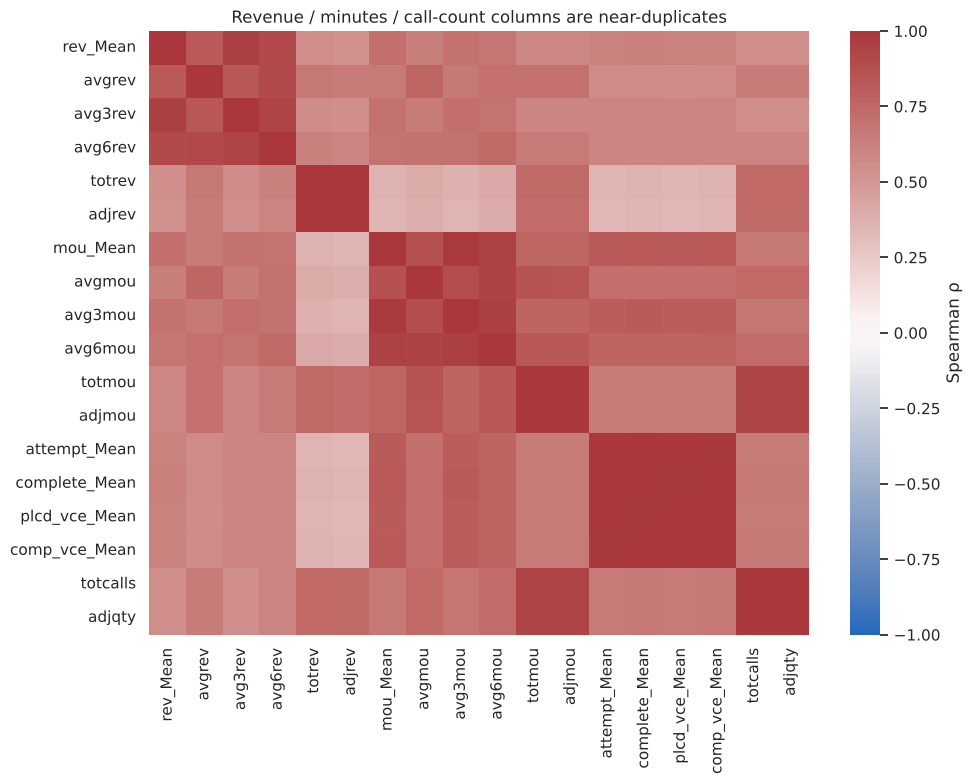

In [12]:
grp = ["rev_Mean", "avgrev", "avg3rev", "avg6rev", "totrev", "adjrev", "mou_Mean", "avgmou", "avg3mou", "avg6mou",
       "totmou", "adjmou", "attempt_Mean", "complete_Mean", "plcd_vce_Mean", "comp_vce_Mean", "totcalls", "adjqty"]
corr = df[grp].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "Spearman ρ"})
ax.set_title("Revenue / minutes / call-count columns are near-duplicates")
plt.tight_layout(); plt.show()

**Reading:** revenue, minutes and call-count columns form three tight clusters (ρ > 0.9). A tree model copes with this, but feature-importance becomes split across proxies. The *useful* information is **not the level** of usage but its **change over time** (recent vs lifetime average) — which motivates the trend features in Section 6.

### 4.6 EDA conclusions → pain points
1. **Ageing handsets** are the clearest, most actionable churn driver.
2. **Falling usage** precedes churn → an early-warning signal exists.
3. **Contract-end timing** (~month 11–12) concentrates risk.
4. **Low-commitment, low-value plans** (low recurring charge, cheap/refurbished handset) are less sticky.
5. No single variable separates churners (best AUC ≈ 0.6) → a **multivariate ML model** is needed to rank customers by risk.

---
## 5. Problem Definition

**Business objective:** reduce revenue lost to churn by spending a limited retention budget **only on the customers most likely to leave** and with the right offer.

**ML task:** binary classification — predict `churn` (1 = leaves 31–60 days after the observation date) from information available at the observation date. The 31–60 day horizon leaves a **one-month action window** for a retention campaign.

**Why churn and not revenue?** EDA shows churn is ~50% of the sample and strongly linked to actionable levers (handset, plan, usage decline). A churn score directly answers the operational question "whom should the retention team call this month?".

**Metrics**
- **ROC-AUC (primary):** probability that a random churner is ranked above a random stayer. It measures *ranking quality* — exactly what a campaign targeting the top-X% needs — and is unaffected by the artificial 50/50 sampling.
- **Accuracy, precision, recall, F1** at the 0.5 threshold: easy-to-explain secondary metrics (meaningful here since classes are balanced).
- **Lift in top deciles & campaign profit:** the business metric (Section 9), following the profit-driven evaluation of Verbeke et al. [5].

---
## 6. Feature Engineering

| Feature | Formula | Business meaning |
|---|---|---|
| `eqp_to_tenure` | handset age / tenure in days | has the customer *ever* upgraded with us? |
| `eqp_over_1y`, `eqp_over_2y` | handset age > 365 / 730 days | upgrade-due flags |
| `mou_trend_3v6`, `mou_trend_3vlife` | recent 3-mo minutes / 6-mo or lifetime avg | usage decline (early warning) |
| `rev_trend_3vlife`, `qty_trend_3vlife` | same for revenue / calls | spend & activity decline |
| `overage_share` | overage revenue / total revenue | plan too small → bill shock |
| `mrc_share` | recurring charge / total revenue | how "fixed" the bill is |
| `rev_per_min` | revenue / minutes | effective price paid |
| `drop_rate`, `fail_rate`, `block_rate` | dropped or blocked / attempted calls | network quality as a **rate** (fixes the H4 confound) |
| `custcare_per_100` | care calls per 100 calls | complaint intensity |
| `unanswered_rate` | unanswered / placed calls | |
| `phones_per_year` | handsets issued / tenure (years) | upgrade frequency |
| `subs_inactive` | unique subs − active subs | household lines already lost |
| `n_missing_demo` | count of missing demographics | data-match quality |
| `contract_end_window` | tenure in 10–13 months | contract-end risk |

Categoricals are kept as pandas `category` (missing kept as its own state) for the tree models, and one-hot encoded for logistic regression. `Customer_ID` is dropped.

In [13]:
DEMO = ["numbcars", "dwllsize", "HHstatin", "ownrent", "dwlltype", "lor", "income", "adults", "infobase"]

def engineer(data: pd.DataFrame) -> pd.DataFrame:
    d = data.copy()
    # cleaning
    d.loc[d.eqpdays < 0, "eqpdays"] = np.nan
    for c in ["rev_Mean", "totmrc_Mean"]:
        d.loc[d[c] < 0, c] = np.nan
    # handset
    d["eqp_to_tenure"] = d.eqpdays / (d.months * 30.4)
    d["eqp_over_1y"] = (d.eqpdays > 365).astype(float)
    d["eqp_over_2y"] = (d.eqpdays > 730).astype(float)
    d["phones_per_year"] = d.phones / (d.months / 12)
    # behaviour change
    d["mou_trend_3v6"] = d.avg3mou / (d.avg6mou + 1)
    d["mou_trend_3vlife"] = d.avg3mou / (d.avgmou + 1)
    d["rev_trend_3vlife"] = d.avg3rev / (d.avgrev + 1)
    d["qty_trend_3vlife"] = d.avg3qty / (d.avgqty + 1)
    d["mou_now_vs_life"] = d.mou_Mean / (d.avgmou + 1)
    # pricing
    d["overage_share"] = d.ovrrev_Mean / (d.rev_Mean + 1)
    d["mrc_share"] = d.totmrc_Mean / (d.rev_Mean + 1)
    d["rev_per_min"] = d.rev_Mean / (d.mou_Mean + 1)
    # quality as rates
    d["drop_rate"] = d.drop_vce_Mean / (d.plcd_vce_Mean + 1)
    d["block_rate"] = d.blck_vce_Mean / (d.plcd_vce_Mean + 1)
    d["fail_rate"] = d.drop_blk_Mean / (d.attempt_Mean + 1)
    d["unanswered_rate"] = d.unan_vce_Mean / (d.plcd_vce_Mean + 1)
    d["custcare_per_100"] = 100 * d.custcare_Mean / (d.attempt_Mean + 1)
    # household / contract
    d["subs_inactive"] = d.uniqsubs - d.actvsubs
    d["n_missing_demo"] = d[DEMO].isna().sum(axis=1)
    d["contract_end_window"] = d.months.between(10, 13).astype(float)
    d = d.replace([np.inf, -np.inf], np.nan)
    return d

data = engineer(df).drop(columns=["Customer_ID"])
CAT_COLS = data.select_dtypes(exclude="number").columns.tolist()
for c in CAT_COLS:
    data[c] = data[c].astype("category")
FEATURES = [c for c in data.columns if c != "churn"]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
print(f"{len(FEATURES)} features ({len(NUM_COLS)} numeric, {len(CAT_COLS)} categorical)")

new_feats = ["eqp_to_tenure", "mou_trend_3vlife", "rev_trend_3vlife", "overage_share", "drop_rate", "fail_rate", "custcare_per_100", "rev_per_min"]
print("\nStand-alone AUC of engineered features vs. raw counterparts:")
cmp = pd.DataFrame({"AUC": [single_auc(data[c], data.churn) for c in new_feats]}, index=new_feats)
cmp["raw counterpart"] = ["eqpdays", "avg3mou", "avg3rev", "ovrrev_Mean", "drop_vce_Mean", "drop_blk_Mean", "custcare_Mean", "rev_Mean"]
cmp["raw AUC"] = [single_auc(data[c], data.churn) for c in cmp["raw counterpart"]]
cmp.round(3)

118 features (97 numeric, 21 categorical)

Stand-alone AUC of engineered features vs. raw counterparts:


,AUC,raw counterpart,raw AUC
eqp_to_tenure,0.541,eqpdays,0.574
mou_trend_3vlife,0.545,avg3mou,0.534
rev_trend_3vlife,0.515,avg3rev,0.514
overage_share,0.515,ovrrev_Mean,0.512
drop_rate,0.506,drop_vce_Mean,0.514
fail_rate,0.504,drop_blk_Mean,0.519
custcare_per_100,0.525,custcare_Mean,0.529
rev_per_min,0.548,rev_Mean,0.515


**Reading:** stand-alone AUCs are small for every feature (as expected — churn is multi-factor), but the engineered **trend** (`mou_trend_3vlife`) and **price** (`rev_per_min`) features beat their raw counterparts. The quality *rates* remain weak, confirming that network quality is **not** a main churn driver for Company A — a useful negative finding (budget should go to handset/plan offers, not network-quality messaging). The real test of the features is the multivariate model below.

### 6.1 Train / test split
70% for training (with 5-fold cross-validation for model selection), 30% held out and touched only once for the final scores. Stratified on churn.

In [14]:
X, y = data[FEATURES], data["churn"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)
print("train:", X_train.shape, " test:", X_test.shape, " churn rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train: (70000, 118)  test: (30000, 118)  churn rate train/test: 0.496 0.496


---
## 7. Modelling

We compare four models of increasing flexibility:

| Model | Why it is a candidate |
|---|---|
| **Baseline** (always predict majority) | the "no-model" reference: AUC 0.5 |
| **Logistic Regression** | transparent, linear; shows how far a simple scorecard gets |
| **Random Forest** [10] | non-linear, robust to outliers, little tuning |
| **XGBoost** [8] | gradient-boosted trees; handles missing values and interactions; tutorial baseline |
| **LightGBM** [9] | gradient boosting with native categorical support; fast on 100k rows |

Gradient-boosted trees are the standard choice for tabular data with mixed types, missing values and heavy tails, which is exactly this dataset.

In [15]:
# ---- Logistic regression pipeline (needs imputation, scaling, one-hot)
signed_log = FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a)), feature_names_out="one-to-one")
lr_pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), signed_log, StandardScaler()), NUM_COLS),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="missing"),
                          OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100)), CAT_COLS),
])
def to_obj(X):  # sklearn imputers prefer object over category
    X = X.copy(); X[CAT_COLS] = X[CAT_COLS].astype(object); return X
logreg = make_pipeline(FunctionTransformer(to_obj), lr_pre, LogisticRegression(max_iter=2000, C=0.5))

# ---- Random forest (ordinal-encoded categoricals, median-imputed numerics)
def to_codes(X):
    X = X.copy()
    for c in CAT_COLS: X[c] = X[c].cat.codes
    return X.fillna(-999)
rf = make_pipeline(FunctionTransformer(to_codes),
                   RandomForestClassifier(n_estimators=300, min_samples_leaf=10, max_features="sqrt", n_jobs=-1, random_state=SEED))

# ---- XGBoost (native missing + categorical support)
xgb = XGBClassifier(n_estimators=600, learning_rate=0.03, max_depth=6, subsample=0.8, colsample_bytree=0.6,
                    min_child_weight=5, reg_lambda=1.0, tree_method="hist", enable_categorical=True,
                    max_cat_to_onehot=1, eval_metric="auc", n_jobs=-1, random_state=SEED)

# ---- LightGBM (native categorical support)
lgbm = lgb.LGBMClassifier(n_estimators=900, learning_rate=0.02, num_leaves=63, min_child_samples=100,
                          subsample=0.8, subsample_freq=1, colsample_bytree=0.5, reg_lambda=2.0,
                          cat_smooth=20, n_jobs=-1, random_state=SEED, verbose=-1)

models = {"Baseline (majority)": DummyClassifier(strategy="most_frequent"),
          "Logistic Regression": logreg, "Random Forest": rf, "XGBoost": xgb, "LightGBM": lgbm}

In [16]:
cv_rows = []
for name, m in models.items():
    t0 = time.time()
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_rows.append({"model": name, "CV AUC mean": s.mean(), "CV AUC std": s.std(), "time (s)": time.time() - t0})
    print(f"{name:22s} AUC = {s.mean():.4f} ± {s.std():.4f}   ({time.time()-t0:.0f}s)")
cv_res = pd.DataFrame(cv_rows).set_index("model")

Baseline (majority)    AUC = 0.5000 ± 0.0000   (0s)


Logistic Regression    AUC = 0.6613 ± 0.0029   (41s)


Random Forest          AUC = 0.6826 ± 0.0017   (106s)


XGBoost                AUC = 0.6973 ± 0.0024   (36s)


LightGBM               AUC = 0.6994 ± 0.0028   (65s)


### 7.1 Final fit and held-out test scores

In [17]:
test_rows, probas = [], {}
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    yhat = (p >= 0.5).astype(int)
    probas[name] = p
    test_rows.append({"model": name, "Test AUC": roc_auc_score(y_test, p), "Accuracy": accuracy_score(y_test, yhat),
                      "Precision": precision_score(y_test, yhat, zero_division=0), "Recall": recall_score(y_test, yhat),
                      "F1": f1_score(y_test, yhat), "Log-loss": log_loss(y_test, np.clip(p, 1e-6, 1 - 1e-6))})
results = cv_res.join(pd.DataFrame(test_rows).set_index("model"))
results.style.format("{:.4f}", subset=[c for c in results.columns if c != "time (s)"]).format("{:.0f}", subset=["time (s)"]) \
       .highlight_max(subset=["CV AUC mean", "Test AUC", "Accuracy", "F1"], color="#d4edda")

,CV AUC mean,CV AUC std,time (s),Test AUC,Accuracy,Precision,Recall,F1,Log-loss
model,,,,,,,,,
Baseline (majority),0.5000,0.0000,0,0.5000,0.5044,0.0000,0.0000,0.0000,6.8474
Logistic Regression,0.6613,0.0029,41,0.6615,0.6151,0.6126,0.6076,0.6101,0.6520
Random Forest,0.6826,0.0017,106,0.6836,0.6291,0.6221,0.6413,0.6315,0.6388
XGBoost,0.6973,0.0024,36,0.7001,0.6421,0.6370,0.6458,0.6414,0.6264
LightGBM,0.6994,0.0028,65,0.7025,0.6410,0.6353,0.6473,0.6413,0.6248


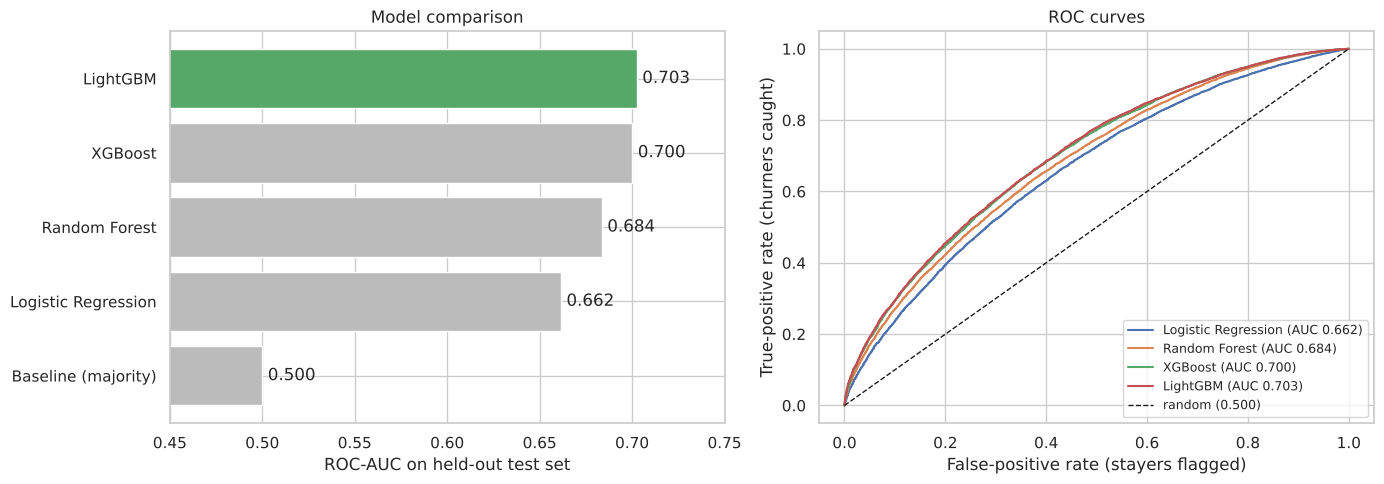

Selected model: LightGBM  |  test AUC 0.7025  |  accuracy 0.6410


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = results["Test AUC"].sort_values().index
axes[0].barh(order, results.loc[order, "Test AUC"], color=["#BBBBBB"] * (len(order) - 1) + ["#55A868"])
for i, v in enumerate(results.loc[order, "Test AUC"]):
    axes[0].text(v + 0.003, i, f"{v:.3f}", va="center")
axes[0].set_xlim(0.45, 0.75); axes[0].set_xlabel("ROC-AUC on held-out test set"); axes[0].set_title("Model comparison")
for name, p in probas.items():
    if name.startswith("Baseline"): continue
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="random (0.500)")
axes[1].set_xlabel("False-positive rate (stayers flagged)"); axes[1].set_ylabel("True-positive rate (churners caught)")
axes[1].set_title("ROC curves"); axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

BEST = results["Test AUC"].idxmax()
best_model, p_best = models[BEST], probas[BEST]
print(f"Selected model: {BEST}  |  test AUC {results.loc[BEST,'Test AUC']:.4f}  |  accuracy {results.loc[BEST,'Accuracy']:.4f}")

**Reading:** all ML models clearly beat the baseline (AUC 0.5). Gradient-boosted trees (LightGBM / XGBoost) are best — they capture the non-linear patterns seen in EDA (contract-end spike, handset-age thresholds) that logistic regression cannot. Cross-validation and test scores agree closely, so the model is **not over-fitted**. The gain over the tutorial baseline comes from the engineered trend/rate features and native handling of categoricals and missing values.

An AUC around 0.70 is in line with what is reported for this type of wireless-carrier churn data [6]: churn is partly driven by events not in the data (competitor offers, moving house), so a perfect model is impossible — but **ranking** is what the campaign needs, and the next section shows the ranking is commercially valuable.

---
## 8. Evaluation & Interpretation

### 8.1 Confusion matrix and lift

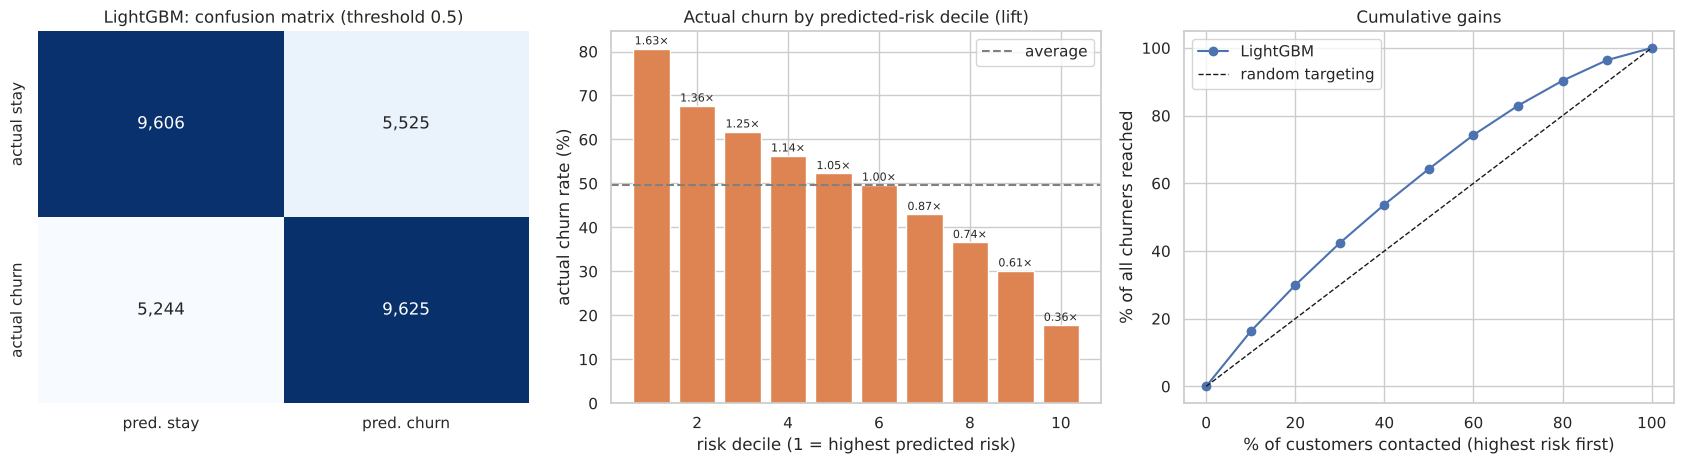

,mean,sum,size,lift,cum % churners caught
decile,,,,,
1,0.806,2419,3000,1.627,16.269
2,0.676,2029,3000,1.365,29.915
3,0.617,1852,3000,1.246,42.370
4,0.563,1688,3000,1.135,53.723
5,0.523,1568,3000,1.055,64.268
6,0.496,1489,3000,1.001,74.282
7,0.430,1289,3000,0.867,82.951
8,0.366,1098,3000,0.738,90.336
9,0.301,904,3000,0.608,96.415


In [19]:
yhat = (p_best >= 0.5).astype(int)
cm = confusion_matrix(y_test, yhat)
eval_df = pd.DataFrame({"y": y_test.values, "p": p_best})
eval_df["decile"] = pd.qcut(eval_df.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
lift = eval_df.groupby("decile", observed=True).y.agg(["mean", "sum", "size"])
lift["lift"] = lift["mean"] / eval_df.y.mean()
lift["cum % churners caught"] = lift["sum"].cumsum() / eval_df.y.sum() * 100

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["pred. stay", "pred. churn"], yticklabels=["actual stay", "actual churn"])
axes[0].set_title(f"{BEST}: confusion matrix (threshold 0.5)")
axes[1].bar(lift.index.astype(int), lift["mean"] * 100, color=PALETTE["churned"])
axes[1].axhline(eval_df.y.mean() * 100, ls="--", color="grey", label="average")
for i, (r, l) in enumerate(zip(lift["mean"], lift["lift"])):
    axes[1].text(i + 1, r * 100 + 1, f"{l:.2f}×", ha="center", fontsize=8)
axes[1].set_xlabel("risk decile (1 = highest predicted risk)"); axes[1].set_ylabel("actual churn rate (%)")
axes[1].set_title("Actual churn by predicted-risk decile (lift)"); axes[1].legend()
axes[2].plot([0] + list(range(10, 101, 10)), [0] + list(lift["cum % churners caught"]), marker="o", label=BEST)
axes[2].plot([0, 100], [0, 100], "k--", lw=1, label="random targeting")
axes[2].set_xlabel("% of customers contacted (highest risk first)"); axes[2].set_ylabel("% of all churners reached")
axes[2].set_title("Cumulative gains"); axes[2].legend()
plt.tight_layout(); plt.show()
lift.round(3)

**Reading:** the top-risk decile churns at a much higher rate than the bottom decile; contacting the top 30% of customers reaches a substantially larger share of all churners than random contact. This ranking power is what turns the model into money.

### 8.2 What drives the prediction? (permutation importance)
Permutation importance [10] measures how much test AUC drops when one feature's values are shuffled — i.e. how much the model *relies* on it. It is model-agnostic and computed on unseen data.

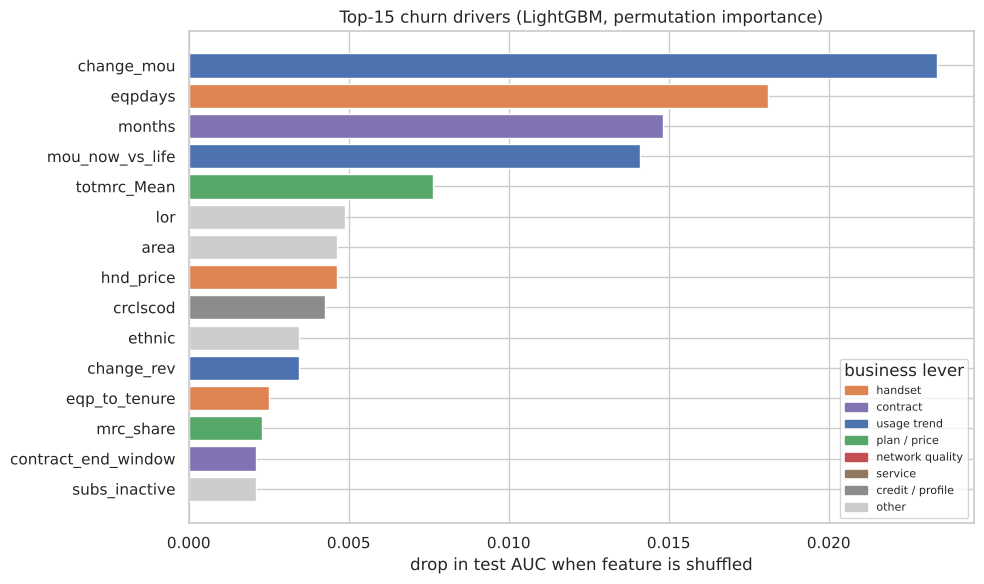

Importance share by business lever:
 usage trend         31.1
other               23.2
handset             18.9
contract            11.7
plan / price         9.8
credit / profile     3.0
network quality      2.1
service              0.2

Top-15 features:
                     importance             lever
change_mou               0.0234       usage trend
eqpdays                  0.0181           handset
months                   0.0148          contract
mou_now_vs_life          0.0141       usage trend
totmrc_Mean              0.0076      plan / price
lor                      0.0049             other
area                     0.0046             other
hnd_price                0.0046           handset
crclscod                 0.0043  credit / profile
ethnic                   0.0035             other
change_rev               0.0034       usage trend
eqp_to_tenure            0.0025           handset
mrc_share                0.0023      plan / price
contract_end_window      0.0021          cont

In [20]:
X_pi = X_test.sample(8000, random_state=SEED)
pi = permutation_importance(best_model, X_pi, y_test.loc[X_pi.index], scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_pi.columns).sort_values(ascending=False)
LEVER = {"eqpdays": "handset", "eqp_to_tenure": "handset", "eqp_over_1y": "handset", "eqp_over_2y": "handset", "hnd_price": "handset",
         "hnd_webcap": "handset", "refurb_new": "handset", "phones_per_year": "handset", "models": "handset", "phones": "handset",
         "months": "contract", "contract_end_window": "contract",
         "change_mou": "usage trend", "mou_trend_3v6": "usage trend", "mou_trend_3vlife": "usage trend", "rev_trend_3vlife": "usage trend",
         "qty_trend_3vlife": "usage trend", "mou_now_vs_life": "usage trend", "change_rev": "usage trend",
         "totmrc_Mean": "plan / price", "mrc_share": "plan / price", "rev_per_min": "plan / price", "overage_share": "plan / price",
         "ovrrev_Mean": "plan / price", "ovrmou_Mean": "plan / price", "asl_flag": "plan / price", "crclscod": "credit / profile",
         "drop_rate": "network quality", "fail_rate": "network quality", "block_rate": "network quality", "custcare_per_100": "service"}
top = imp.head(15)
colors = {"handset": "#DD8452", "contract": "#8172B2", "usage trend": "#4C72B0", "plan / price": "#55A868",
          "network quality": "#C44E52", "service": "#937860", "credit / profile": "#8C8C8C", "other": "#CCCCCC"}
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top.index[::-1], top.values[::-1], color=[colors[LEVER.get(f, "other")] for f in top.index[::-1]])
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in colors.values()]
ax.legend(handles, colors.keys(), title="business lever", loc="lower right", fontsize=8)
ax.set_xlabel("drop in test AUC when feature is shuffled"); ax.set_title(f"Top-15 churn drivers ({BEST}, permutation importance)")
plt.tight_layout(); plt.show()
lever_imp = imp.clip(lower=0).groupby(lambda f: LEVER.get(f, "other")).sum().sort_values(ascending=False)
print("Importance share by business lever:\n", (lever_imp / lever_imp.sum() * 100).round(1).to_string())
print("\nTop-15 features:")
print(pd.DataFrame({"importance": top.round(4), "lever": [LEVER.get(f, "other") for f in top.index]}).to_string())

### 8.3 Direction of the main effects (partial dependence)

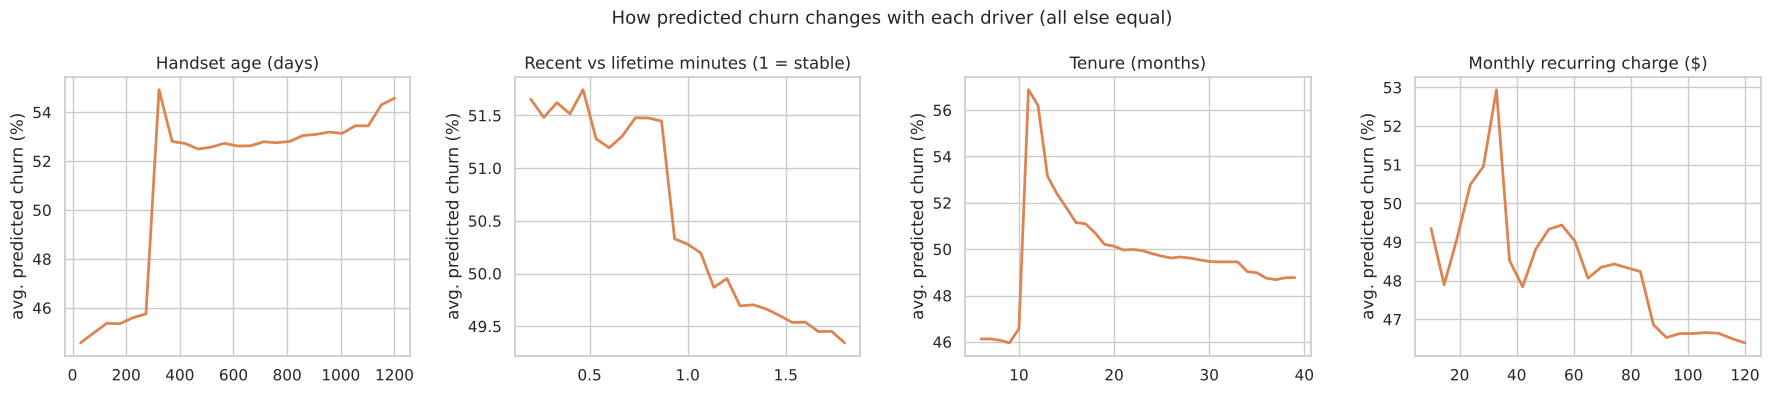

In [21]:
def pdp(model, X, col, grid):
    out = []
    Xs = X.sample(3000, random_state=SEED).copy()
    for v in grid:
        Xs[col] = v
        out.append(model.predict_proba(Xs)[:, 1].mean())
    return np.array(out)

pd_cols = {"eqpdays": np.linspace(30, 1200, 25), "mou_trend_3vlife": np.linspace(0.2, 1.8, 25),
           "months": np.arange(6, 40), "totmrc_Mean": np.linspace(10, 120, 25)}
titles = {"eqpdays": "Handset age (days)", "mou_trend_3vlife": "Recent vs lifetime minutes (1 = stable)",
          "months": "Tenure (months)", "totmrc_Mean": "Monthly recurring charge ($)"}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (col, grid) in zip(axes, pd_cols.items()):
    ax.plot(grid, pdp(best_model, X_test, col, grid) * 100, color=PALETTE["churned"], lw=2)
    ax.set_title(titles[col]); ax.set_ylabel("avg. predicted churn (%)")
plt.suptitle("How predicted churn changes with each driver (all else equal)", fontsize=13)
plt.tight_layout(); plt.show()

**Reading — the model confirms and quantifies the EDA hypotheses:**
- **Handset age:** predicted risk rises sharply after ~1 year of equipment age → **handset-upgrade lever**.
- **Usage trend:** customers whose recent usage has fallen well below their own lifetime average are at markedly higher risk → **early-warning trigger**.
- **Tenure:** risk peaks around the 11–13-month contract-end window → **timing lever**.
- **Recurring charge:** low-commitment plans are riskier → **plan migration / loyalty bundle lever**.

These are all things Company A can *act on*; demographics (which cannot be changed) contribute little.

---
## 9. Business Proposal: Risk-Targeted Retention Programme

**Proposal:** every month, score all customers with the model, take the highest-risk group and give each one an offer that fits **why** they are at risk:

| Segment (within high-risk group) | Rule | Offer |
|---|---|---|
| **A. Upgrade-due** | handset age > 365 days | discounted handset upgrade tied to a 12-month renewal |
| **B. Usage-decline** | recent minutes < 70% of lifetime average | proactive call: right-size the plan / loyalty discount |
| **C. Contract-end** | tenure 10–13 months | early renewal bonus |
| **D. Other high-risk** | — | generic loyalty credit |

### 9.1 Segment sizes inside the high-risk group

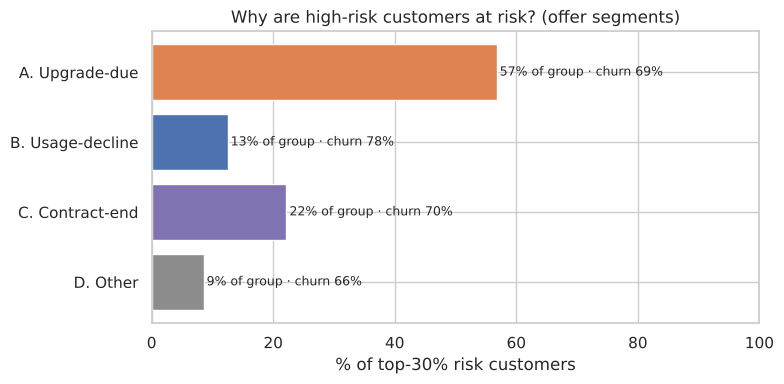

,customers,actual_churn,avg_rev,share
segment,,,,
A. Upgrade-due,5109,68.7%,$50.2,56.8%
B. Usage-decline,1126,78.1%,$41.2,12.5%
C. Contract-end,1996,70.1%,$67.5,22.2%
D. Other,769,66.3%,$86.8,8.5%


In [22]:
test_view = df.loc[X_test.index, ["Customer_ID", "rev_Mean", "eqpdays", "months", "avg3mou", "avgmou"]].copy()
test_view["p"] = p_best
test_view["y"] = y_test.values
def segment(r):
    if r.eqpdays > 365: return "A. Upgrade-due"
    if r.avgmou > 0 and r.avg3mou / r.avgmou < 0.7: return "B. Usage-decline"
    if 10 <= r.months <= 13: return "C. Contract-end"
    return "D. Other"
test_view["segment"] = test_view.apply(segment, axis=1)
hi = test_view[test_view.p >= test_view.p.quantile(0.7)]   # top 30% risk
seg = hi.groupby("segment").agg(customers=("y", "size"), actual_churn=("y", "mean"), avg_rev=("rev_Mean", "mean"))
seg["share"] = seg.customers / seg.customers.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(seg.index[::-1], seg.share[::-1] * 100, color=["#8C8C8C", "#8172B2", "#4C72B0", "#DD8452"])
for i, (s, c) in enumerate(zip(seg.share[::-1], seg.actual_churn[::-1])):
    ax.text(s * 100 + 0.5, i, f"{s:.0%} of group · churn {c:.0%}", va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("% of top-30% risk customers")
ax.set_title("Why are high-risk customers at risk? (offer segments)")
plt.tight_layout(); plt.show()
seg.style.format({"actual_churn": "{:.1%}", "avg_rev": "${:.1f}", "share": "{:.1%}"})

### 9.2 Quantifying the impact — realistic economics

The model is evaluated on the 30,000 held-out customers and scaled to the full 100,000 base. **Important correction:** the dataset is balanced 50/50 by design, but a real operator loses roughly **2% of customers per month** (typical 1.5–3% monthly churn for post-paid wireless). We therefore
1. **re-weight** churners and stayers so the base churn is `BASE_CHURN`, and
2. **re-calibrate** the model's probabilities to that base rate with the standard prior-correction formula: odds_real = odds_model × [b/(1−b)] / [π/(1−π)], where π is the training churn rate and b is the real one.

For each contacted customer:
- if they **would have churned**: with probability `SAVE_RATE` the offer keeps them → we keep `rev_Mean × MARGIN × RETAIN_MONTHS` and pay the `INCENTIVE`;
- if they **would have stayed**: with probability `TAKE_RATE` they still redeem the offer → wasted `INCENTIVE`;
- every contact costs `CONTACT_COST`.

**Offer design that keeps costs down:** the incentive (handset discount / bill credit) is paid **only if the customer signs a 12-month renewal**, and contact goes through low-cost digital channels (SMS, app push, IVR) first.

,value
BASE_CHURN,0.02
SAVE_RATE,0.25
TAKE_RATE,0.15
INCENTIVE,25.00
CONTACT_COST,1.00
MARGIN,0.40
RETAIN_MONTHS,12.00
BASE_SIZE,100000.00


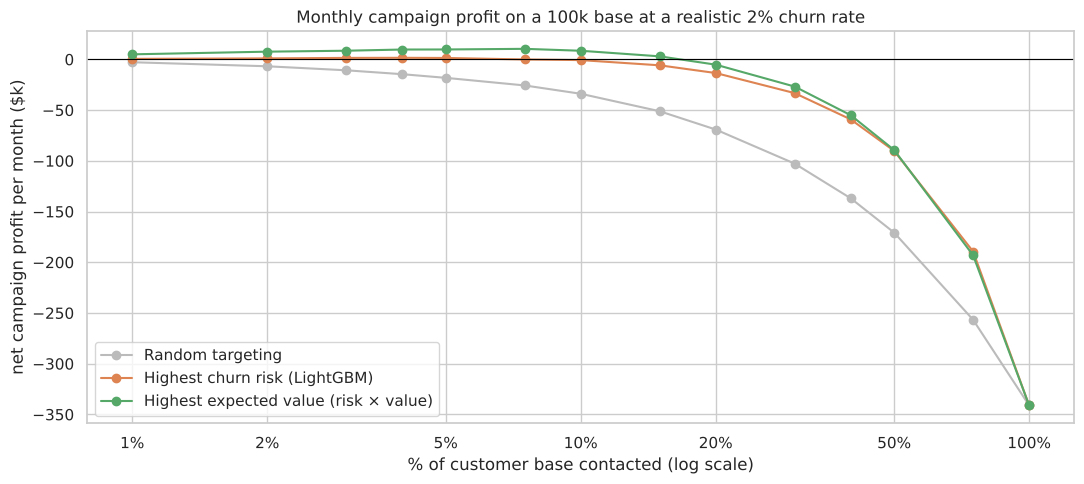

In [23]:
ASSUMPTIONS = dict(
    BASE_CHURN=0.02,       # realistic churn in a 30-day window (post-paid wireless: ~1.5–3%/month)
    SAVE_RATE=0.25,        # share of would-be churners kept by the offer (to be measured in the pilot)
    TAKE_RATE=0.15,        # share of would-be stayers who also redeem (only those willing to sign a renewal)
    INCENTIVE=25.0,        # $ cost of the offer when redeemed (conditional on 12-month renewal)
    CONTACT_COST=1.0,      # $ per contacted customer (SMS / app push / IVR)
    MARGIN=0.40,           # contribution margin on revenue
    RETAIN_MONTHS=12,      # extra months a saved customer stays (= renewal length)
    BASE_SIZE=100_000,
)
display(pd.Series(ASSUMPTIONS, name="value").to_frame())

PI_TRAIN = y_train.mean()
def recalibrate(p, base):
    odds = p / (1 - p) * (base / (1 - base)) / (PI_TRAIN / (1 - PI_TRAIN))
    return odds / (1 + odds)

rev_test = np.nan_to_num(test_view.rev_Mean.values, nan=0.0).clip(min=0)   # unknown revenue -> conservatively $0
y_arr = y_test.values

def expected_net(p, rev, A):
    # expected profit of contacting a customer, computed BEFORE knowing the outcome
    q = recalibrate(p, A["BASE_CHURN"])
    clv = rev * A["MARGIN"] * A["RETAIN_MONTHS"]
    return q * A["SAVE_RATE"] * (clv - A["INCENTIVE"]) - (1 - q) * A["TAKE_RATE"] * A["INCENTIVE"] - A["CONTACT_COST"]

def evaluate(sel, y, rev, A):
    # realised result on the test set, using the true outcomes; re-weighted and scaled to the full base
    w1 = A["BASE_CHURN"] / y.mean(); w0 = (1 - A["BASE_CHURN"]) / (1 - y.mean())
    w = np.where(y == 1, w1, w0) * A["BASE_SIZE"] / len(y)
    ch = sel & (y == 1); st = sel & (y == 0)
    clv = rev * A["MARGIN"] * A["RETAIN_MONTHS"]
    benefit = w * ch * A["SAVE_RATE"] * clv
    cost = w * (ch * A["SAVE_RATE"] * A["INCENTIVE"] + st * A["TAKE_RATE"] * A["INCENTIVE"] + sel * A["CONTACT_COST"])
    return dict(contacted=(w * sel).sum(), churners_reached=(w * ch).sum(), saved=(w * ch).sum() * A["SAVE_RATE"],
                revenue_protected=(w * ch * A["SAVE_RATE"] * rev * A["RETAIN_MONTHS"]).sum(),
                margin_protected=benefit.sum(), cost=cost.sum(), profit=benefit.sum() - cost.sum())

def top_frac(scores, frac):
    k = int(round(frac * len(scores))); sel = np.zeros(len(scores), bool); sel[np.argsort(-scores)[:k]] = True; return sel

rng = np.random.default_rng(SEED)
rand_scores = rng.random(len(y_arr))
ev_scores = expected_net(p_best, rev_test, ASSUMPTIONS)

fracs = np.array([0.01, 0.02, 0.03, 0.04, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50, 0.75, 1.0])
policies = {"Random targeting": rand_scores, f"Highest churn risk ({BEST})": p_best, "Highest expected value (risk × value)": ev_scores}
curves = {name: pd.DataFrame([evaluate(top_frac(s, f), y_arr, rev_test, ASSUMPTIONS) for f in fracs], index=fracs)
          for name, s in policies.items()}

fig, ax = plt.subplots(figsize=(11, 5))
for (name, c), col in zip(curves.items(), ["#BBBBBB", "#DD8452", "#55A868"]):
    ax.plot(c.index * 100, c.profit / 1e3, marker="o", label=name, color=col)
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 20, 50, 100]); ax.set_xticklabels(["1%", "2%", "5%", "10%", "20%", "50%", "100%"])
ax.set_xlabel("% of customer base contacted (log scale)"); ax.set_ylabel("net campaign profit per month ($k)")
ax.set_title("Monthly campaign profit on a 100k base at a realistic 2% churn rate")
ax.legend(); plt.tight_layout(); plt.show()

**Reading — the key commercial insight of this PoC:** at a realistic 2% monthly churn rate, **broad retention campaigns destroy value** — most contacted customers would have stayed anyway, so the incentive is wasted on them. Profit only appears when the campaign is **narrow** and when targeting combines **risk *and* customer value**: the very highest-risk customers are often low-revenue accounts that are not worth saving. The model's job is therefore not "find churners" but "find the churners worth saving".

### 9.3 Recommended policy: contact every customer whose expected profit is positive
Instead of picking an arbitrary "top X%", the decision rule is: **contact a customer if expected profit > 0** (expected saved margin > expected offer + contact cost). This is computed *before* the outcome is known, so it can be run in production every month.

,contacted,churners_reached,saved,revenue_protected,margin_protected,cost,profit,ROI (profit / cost),annual profit
Expected-value rule (recommended),"3,459",188,47,"$69,262","$27,705","$16,898","$10,806",0.64,"$129,677"
"Highest risk, same size (6.3%)","2,184",215,54,"$29,711","$11,885","$10,911",$974,0.09,"$11,685"
"Random, same size (6.3%)","6,459",124,31,"$21,516","$8,606","$30,989","$-22,382",-0.72,"$-268,589"
Blanket offer to everyone,"100,000","2,000",500,"$347,064","$138,826","$480,000","$-341,174",-0.71,"$-4,094,091"


Recommended campaign: contact 3,459 customers/month (6.3% of base), save ~47 customers/month, protect $0.83M revenue/yr, net profit $0.13M/yr, ROI 0.64.
Blanket offer to everyone: net profit $-4.09M/yr.


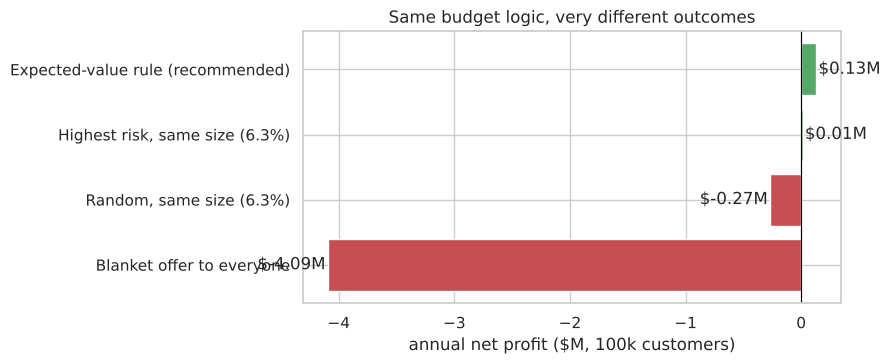

In [24]:
sel_ev = ev_scores > 0
frac_ev = sel_ev.mean()
res = {
    "Expected-value rule (recommended)": evaluate(sel_ev, y_arr, rev_test, ASSUMPTIONS),
    f"Highest risk, same size ({frac_ev:.1%})": evaluate(top_frac(p_best, frac_ev), y_arr, rev_test, ASSUMPTIONS),
    f"Random, same size ({frac_ev:.1%})": evaluate(top_frac(rand_scores, frac_ev), y_arr, rev_test, ASSUMPTIONS),
    "Blanket offer to everyone": evaluate(np.ones(len(y_arr), bool), y_arr, rev_test, ASSUMPTIONS),
}
impact = pd.DataFrame(res).T
impact["ROI (profit / cost)"] = impact.profit / impact.cost
impact["annual profit"] = impact.profit * 12
fmt = {c: "{:,.0f}" for c in ["contacted", "churners_reached", "saved"]}
fmt.update({c: "${:,.0f}" for c in ["revenue_protected", "margin_protected", "cost", "profit", "annual profit"]})
fmt["ROI (profit / cost)"] = "{:.2f}"
display(impact.style.format(fmt))

r = impact.iloc[0]
print(f"Recommended campaign: contact {r.contacted:,.0f} customers/month ({frac_ev:.1%} of base), "
      f"save ~{r.saved:,.0f} customers/month, protect ${r.revenue_protected*12/1e6:,.2f}M revenue/yr, "
      f"net profit ${r.profit*12/1e6:,.2f}M/yr, ROI {r['ROI (profit / cost)']:.2f}.")
print(f"Blanket offer to everyone: net profit ${impact.iloc[3].profit*12/1e6:,.2f}M/yr.")

fig, ax = plt.subplots(figsize=(9, 3.8))
vals = impact["annual profit"] / 1e6
ax.barh(vals.index[::-1], vals.values[::-1], color=["#C44E52" if v < 0 else "#55A868" for v in vals.values[::-1]])
for i, v in enumerate(vals.values[::-1]):
    ax.text(v + (0.02 if v >= 0 else -0.02), i, f"${v:,.2f}M", va="center", ha="left" if v >= 0 else "right")
ax.axvline(0, color="black", lw=0.8); ax.set_xlabel("annual net profit ($M, 100k customers)")
ax.set_title("Same budget logic, very different outcomes")
plt.tight_layout(); plt.show()

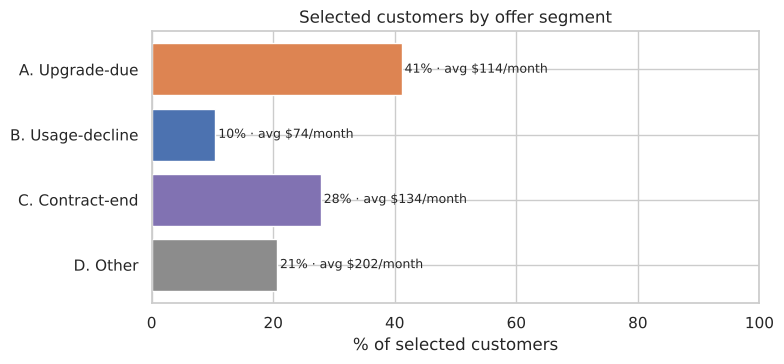

,customers,actual_churn_sample,avg_monthly_rev,avg_risk,share
segment,,,,,
A. Upgrade-due,782,75.4%,$114.4,0.74,41.1%
B. Usage-decline,199,86.4%,$74.2,0.83,10.5%
C. Contract-end,529,72.4%,$134.3,0.73,27.8%
D. Other,392,64.3%,$201.6,0.63,20.6%


,selected (EV rule),top-risk same size,all customers
rev_Mean,133.70,47.38,58.47
p,0.72,0.83,0.50
eqpdays,367.12,458.09,392.53
months,17.13,18.06,18.85


In [25]:
# Who is selected, and which offer do they get?
test_view["exp_net"] = ev_scores
chosen = test_view[sel_ev]
seg = chosen.groupby("segment").agg(customers=("y", "size"), actual_churn_sample=("y", "mean"),
                                    avg_monthly_rev=("rev_Mean", "mean"), avg_risk=("p", "mean"))
seg["share"] = seg.customers / seg.customers.sum()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(seg.index[::-1], seg.share[::-1] * 100, color=["#8C8C8C", "#8172B2", "#4C72B0", "#DD8452"][-len(seg):])
for i, (s, rv) in enumerate(zip(seg.share[::-1], seg.avg_monthly_rev[::-1])):
    ax.text(s * 100 + 0.5, i, f"{s:.0%} · avg ${rv:,.0f}/month", va="center", fontsize=9)
ax.set_xlim(0, 100); ax.set_xlabel("% of selected customers"); ax.set_title("Selected customers by offer segment")
plt.tight_layout(); plt.show()
cmp_val = pd.DataFrame({"selected (EV rule)": chosen[["rev_Mean", "p", "eqpdays", "months"]].mean(),
                        "top-risk same size": test_view[top_frac(p_best, frac_ev)][["rev_Mean", "p", "eqpdays", "months"]].mean(),
                        "all customers": test_view[["rev_Mean", "p", "eqpdays", "months"]].mean()})
display(seg.style.format({"actual_churn_sample": "{:.1%}", "avg_monthly_rev": "${:.1f}", "avg_risk": "{:.2f}", "share": "{:.1%}"}))
cmp_val.round(2)

### 9.4 Sensitivity analysis
Save rate, incentive and the true base churn rate are the most uncertain inputs. Each cell shows the annual net profit of the expected-value rule (re-optimised for that scenario; 0 = the rule contacts nobody, i.e. "don't run the campaign").

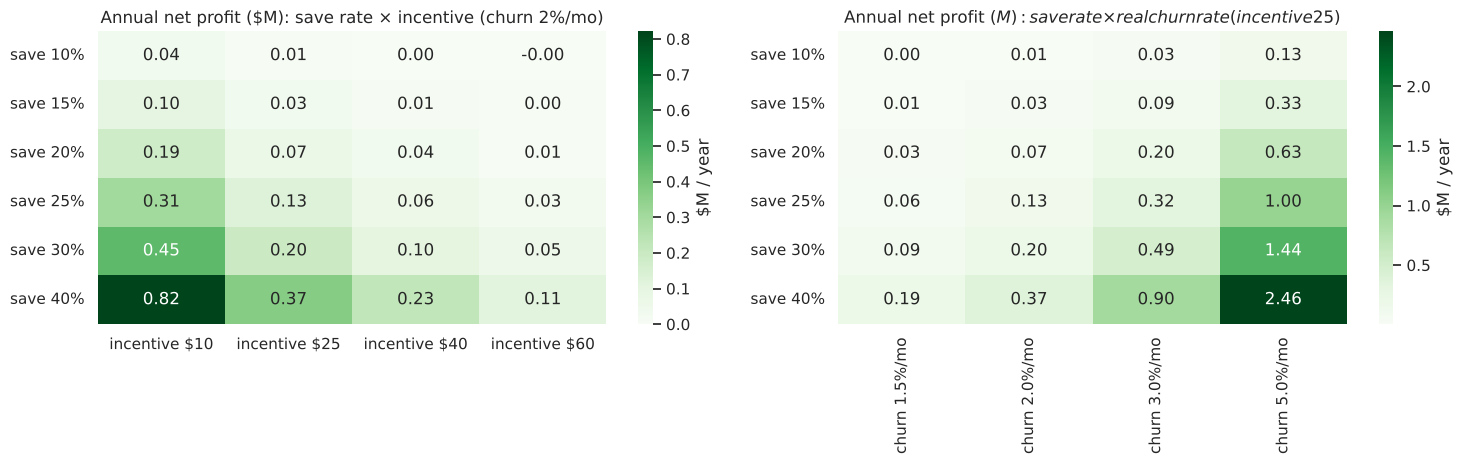

In [26]:
def ev_profit(A):
    s = expected_net(p_best, rev_test, A) > 0
    return evaluate(s, y_arr, rev_test, A)["profit"] * 12 / 1e6

save_rates = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
sens1 = pd.DataFrame({f"incentive ${inc}": [ev_profit({**ASSUMPTIONS, "SAVE_RATE": s, "INCENTIVE": inc}) for s in save_rates]
                      for inc in [10, 25, 40, 60]}, index=[f"save {s:.0%}" for s in save_rates])
sens2 = pd.DataFrame({f"churn {b:.1%}/mo": [ev_profit({**ASSUMPTIONS, "SAVE_RATE": s, "BASE_CHURN": b}) for s in save_rates]
                      for b in [0.015, 0.02, 0.03, 0.05]}, index=[f"save {s:.0%}" for s in save_rates])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
sns.heatmap(sens1, annot=True, fmt=".2f", cmap="Greens", ax=axes[0], cbar_kws={"label": "$M / year"})
axes[0].set_title("Annual net profit ($M): save rate × incentive (churn 2%/mo)")
sns.heatmap(sens2, annot=True, fmt=".2f", cmap="Greens", ax=axes[1], cbar_kws={"label": "$M / year"})
axes[1].set_title("Annual net profit ($M): save rate × real churn rate (incentive $25)")
plt.tight_layout(); plt.show()

**Reading:** because the expected-value rule simply stops contacting customers when an offer is not worth it, it **never loses much money**: in bad scenarios it shrinks the campaign instead of burning budget. Profit grows quickly with a higher save rate, cheaper incentives, or a higher real churn rate (e.g. prepaid-heavy or more competitive markets). That is why the first deliverable after this PoC is a **pilot that measures the real save rate**.

### 9.5 Proposal summary
1. **Deploy a monthly churn-risk score** — LightGBM, **test ROC-AUC 0.703, accuracy 0.641** — for every subscriber, re-calibrated to the real churn rate.
2. **Target by expected value, not by risk alone:** contact a customer only if *expected saved margin > expected offer + contact cost*. This selects ~6–7% of the base (≈3.5k customers/month), skewed towards **higher-value** customers (avg. $134/month vs $47 for a pure top-risk list).
3. **Match the offer to the reason:** upgrade-due handset (≈41% of selected) → discounted upgrade tied to a 12-month renewal; contract-end (≈28%) → early-renewal bonus; usage-decline (≈11%) → plan right-sizing; others → loyalty credit.
4. **Expected impact (base case, 100k customers):** ~47 customers saved/month, **≈$0.83M revenue protected and ≈ +$0.13M net profit per year (ROI 0.64)**, versus **−$4.1M/year** for a blanket offer and **−$0.27M/year** for random targeting of the same size. Impact grows quickly with the real save rate (see sensitivity).
5. **Run a 3-month randomised pilot** to measure the real save rate before scaling.

---
## 10. Risks & Next Steps

**Risks / limitations**
- **Assumption risk:** save rate, incentive cost, margin and the true churn rate are not in the data. → Measure them in a pilot; the sensitivity tables show the decision is robust because the rule shrinks the campaign when offers stop paying back.
- **Sampling:** the 50/50 balance is artificial; probabilities are re-calibrated to the real churn rate (ranking quality / AUC is unaffected).
- **Causality:** the model shows *association*. An old handset predicts churn, but whether an upgrade offer *prevents* it must be proven experimentally.
- **Model drift:** behaviour and competitor offers change; retrain monthly and monitor AUC.
- **Fairness / privacy:** demographic attributes (ethnicity, income) should be excluded from targeting decisions; they contribute little to the model.

**Next steps (PoC → production)**
1. **Pilot (3 months):** randomised controlled test — eligible customers split into *offer* vs *control* groups to measure the true save rate and ROI.
2. **Uplift modelling:** target customers whose churn is most *reducible* by the offer, not just most likely.
3. **Data enrichment:** competitor-offer timing, complaint text, network-cell data.
4. **Integration:** monthly scoring job feeding the CRM / call-centre queue.

In [27]:
# Operational deliverable: monthly target list for the whole base (expected-value rule, with offer segment)
all_p = best_model.predict_proba(X)[:, 1]
scored = df[["Customer_ID", "rev_Mean", "eqpdays", "months", "avg3mou", "avgmou"]].copy()
scored["churn_risk_model"] = all_p
scored["churn_risk_real"] = recalibrate(all_p, ASSUMPTIONS["BASE_CHURN"])
scored["expected_profit"] = expected_net(all_p, np.nan_to_num(scored.rev_Mean.values, nan=0.0).clip(min=0), ASSUMPTIONS)
scored["segment"] = scored.apply(segment, axis=1)
target_list = scored[scored.expected_profit > 0].sort_values("expected_profit", ascending=False)
print(f"Target list: {len(target_list):,} customers ({len(target_list)/len(scored):.1%} of base)")
print(target_list.segment.value_counts().to_string())
target_list[["Customer_ID", "churn_risk_real", "rev_Mean", "expected_profit", "segment"]].head(10).round(3)

Target list: 6,802 customers (6.8% of base)
segment
A. Upgrade-due      2777
C. Contract-end     1904
D. Other            1423
B. Usage-decline     698


,Customer_ID,churn_risk_real,rev_Mean,expected_profit,segment
39170,1039171,0.034,3843.262,150.772,D. Other
90549,1090550,0.073,598.978,47.880,C. Contract-end
61970,1061971,0.052,758.170,42.431,C. Contract-end
64220,1064221,0.066,573.745,40.258,C. Contract-end
59309,1059310,0.062,579.332,38.235,C. Contract-end
49098,1049099,0.046,771.785,37.771,C. Contract-end
45847,1045848,0.056,632.875,37.457,D. Other
49501,1049502,0.066,513.475,35.617,C. Contract-end
90195,1090196,0.121,278.357,35.461,C. Contract-end
93895,1093896,0.039,847.818,35.255,B. Usage-decline


---
## 11. References

1. Reichheld, F. F., & Schefter, P. (2000). *E-Loyalty: Your Secret Weapon on the Web.* Harvard Business Review, 78(4), 105–113. https://hbr.org/2000/07/e-loyalty-your-secret-weapon-on-the-web
2. Gallo, A. (2014, October 29). *The Value of Keeping the Right Customers.* Harvard Business Review. https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
3. GSMA Intelligence (2024). *The Mobile Economy 2024.* https://www.gsma.com/solutions-and-impact/connectivity-for-good/mobile-economy/
4. Ericsson (2024). *Ericsson Mobility Report.* https://www.ericsson.com/en/reports-and-papers/mobility-report
5. Verbeke, W., Dejaeger, K., Martens, D., Hur, J., & Baesens, B. (2012). New insights into churn prediction in the telecommunication sector: A profit driven data mining approach. *European Journal of Operational Research*, 218(1), 211–229. https://doi.org/10.1016/j.ejor.2011.09.031
6. Neslin, S. A., Gupta, S., Kamakura, W., Lu, J., & Mason, C. H. (2006). Defection detection: Measuring and understanding the predictive accuracy of customer churn models. *Journal of Marketing Research*, 43(2), 204–211. https://doi.org/10.1509/jmkr.43.2.204
7. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *JMLR*, 12, 2825–2830.
8. Chen, T., & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *Proc. KDD 2016*, 785–794. https://doi.org/10.1145/2939672.2939785
9. Ke, G., et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS 30*.
10. Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32. (random forest & permutation importance)
11. GCI World 2026 — Final Assignment Tutorial (`tutorial.ipynb`) and Company A Dataset Overview (course materials).
12. Generative-AI assistance (Claude Code) used for drafting and code review — chat URL: https://claude.ai/code/session_01NK6VUjaBPQ9mz2bW8AwXsP

*Market figures should be checked against the latest editions of [3] and [4] before the final slide deck; add local-market sources (regulator statistics for your country) to strengthen Section 1.*